In [1]:
%pip install pandas numpy scikit-learn ctgan matplotlib seaborn psutil

Note: you may need to restart the kernel to use updated packages.


# Step 1: Import libraries and load the dataset

In [5]:
# 1. Import required libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import psutil

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Libraries imported successfully!")

# 2. Define dataset file paths
# Both CSV files are uploaded to your Jupyter home folder.

train_path = "UNSW_NB15_training-set.csv"
test_path = "UNSW_NB15_testing-set.csv"

# 3. Check whether the files exist
print("\nChecking dataset files...")

if not os.path.exists(train_path):
    raise FileNotFoundError(
        f"Training file not found: {train_path}. "
        "Make sure it is uploaded to the current Jupyter folder."
    )

if not os.path.exists(test_path):
    raise FileNotFoundError(
        f"Testing file not found: {test_path}. "
        "Make sure it is uploaded to the current Jupyter folder."
    )

print("Training file found:", train_path)
print("Testing file found:", test_path)

# 4. Load the datasets
train_data = pd.read_csv(train_path, low_memory=False)
test_data = pd.read_csv(test_path, low_memory=False)

print("\nDatasets loaded successfully!")

# 5. Display dataset dimensions
print("\nTraining dataset shape:", train_data.shape)
print("Testing dataset shape:", test_data.shape)

# 6. Display the first five rows
print("\nTraining dataset preview:")
display(train_data.head())

# 7. Display column names
print("\nAvailable columns:")
print(train_data.columns.tolist())

# 8. Check missing values
print("\nTotal missing values in training data:",
      train_data.isnull().sum().sum())

print("Total missing values in testing data:",
      test_data.isnull().sum().sum())

# 9. Check duplicate rows
print("\nDuplicate rows in training data:",
      train_data.duplicated().sum())

print("Duplicate rows in testing data:",
      test_data.duplicated().sum())

# 10. Display memory availability
available_ram = psutil.virtual_memory().available / (1024 ** 3)

print("\nAvailable RAM:", round(available_ram, 2), "GB")

print("\nSTEP 1 COMPLETED SUCCESSFULLY!")

Libraries imported successfully!

Checking dataset files...
Training file found: UNSW_NB15_training-set.csv
Testing file found: UNSW_NB15_testing-set.csv

Datasets loaded successfully!

Training dataset shape: (82332, 45)
Testing dataset shape: (175341, 45)

Training dataset preview:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0



Available columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Total missing values in training data: 0
Total missing values in testing data: 0

Duplicate rows in training data: 0
Duplicate rows in testing data: 0

Available RAM: 7.69 GB

STEP 1 COMPLETED SUCCESSFULLY!


In [6]:
# Verify the training and testing datasets

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

print("\nTraining labels:")
print(train_data["label"].value_counts(dropna=False))

print("\nTraining attack categories:")
print(train_data["attack_cat"].value_counts(dropna=False))

print("\nTesting labels:")
print(test_data["label"].value_counts(dropna=False))

print("\nTesting attack categories:")
print(test_data["attack_cat"].value_counts(dropna=False))

Training shape: (82332, 45)
Testing shape: (175341, 45)

Training labels:
label
1    45332
0    37000
Name: count, dtype: int64

Training attack categories:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

Testing labels:
label
1    119341
0     56000
Name: count, dtype: int64

Testing attack categories:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [8]:
train_data, test_data = test_data, train_data

print("Corrected training shape:", train_data.shape)
print("Corrected testing shape:", test_data.shape)

print("\nTraining attack distribution:")
print(train_data["attack_cat"].value_counts())

print("\nTesting attack distribution:")
print(test_data["attack_cat"].value_counts())

Corrected training shape: (82332, 45)
Corrected testing shape: (175341, 45)

Training attack distribution:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

Testing attack distribution:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


# Step 2 — Data preprocessing

In [9]:
# 1. Check dataset dimensions
print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

# 2. Check column names and data types
print("\nTraining dataset information:")
train_data.info()

# 3. Check missing values
print("\nMissing values in training data:")
print(train_data.isnull().sum()[train_data.isnull().sum() > 0])

print("\nMissing values in testing data:")
print(test_data.isnull().sum()[test_data.isnull().sum() > 0])

# 4. Check duplicate records
print("\nDuplicate rows in training data:",
      train_data.duplicated().sum())

print("Duplicate rows in testing data:",
      test_data.duplicated().sum())

# 5. Check categorical columns
categorical_columns = train_data.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nCategorical columns:")
print(categorical_columns)

# 6. Check target columns
print("\nLabel column values:")
print(train_data["label"].value_counts(dropna=False))

print("\nAttack category values:")
print(train_data["attack_cat"].value_counts(dropna=False))

# 7. Check infinite numeric values
numeric_columns = train_data.select_dtypes(
    include=[np.number]
).columns

print("\nInfinite values in training data:")
print(np.isinf(train_data[numeric_columns]).sum().sum())

print("\nSTEP 2 INITIAL INSPECTION COMPLETED!")

Training shape: (82332, 45)
Testing shape: (175341, 45)

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82332 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 82332 non-null  int64  
 1   dur                82332 non-null  float64
 2   proto              82332 non-null  object 
 3   service            82332 non-null  object 
 4   state              82332 non-null  object 
 5   spkts              82332 non-null  int64  
 6   dpkts              82332 non-null  int64  
 7   sbytes             82332 non-null  int64  
 8   dbytes             82332 non-null  int64  
 9   rate               82332 non-null  float64
 10  sttl               82332 non-null  int64  
 11  dttl               82332 non-null  int64  
 12  sload              82332 non-null  float64
 13  dload              82332 non-null  float64
 14  sloss              82332 non-nu

In [10]:
# Correct the dataset assignment only if the shapes are reversed

if train_data.shape[0] == 82332 and test_data.shape[0] == 175341:
    train_data, test_data = test_data, train_data

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

assert train_data.shape[0] == 175341, "Check training dataset assignment"
assert test_data.shape[0] == 82332, "Check testing dataset assignment"

print("\nDataset assignment verified!")

Training shape: (175341, 45)
Testing shape: (82332, 45)

Dataset assignment verified!


In [11]:
# STEP 2: Final preprocessing checks
# 1. Verify dataset dimensions
print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

# 2. Check categorical values
categorical_columns = ["proto", "service", "state", "attack_cat"]

for col in categorical_columns:
    print(f"\n{col} — training unique values: {train_data[col].nunique()}")
    print("Blank strings:", (train_data[col].astype(str).str.strip() == "").sum())
    print("Missing values:", train_data[col].isna().sum())

# 3. Check target consistency
print("\nLabel and attack category consistency:")
print(pd.crosstab(train_data["attack_cat"], train_data["label"]))

# 4. Confirm the rare target category
print("\nWorms records in training data:",
      (train_data["attack_cat"] == "Worms").sum())

print("\nWorms records in testing data:",
      (test_data["attack_cat"] == "Worms").sum())

print("\nSTEP 2 CHECKS COMPLETED!")

Training shape: (175341, 45)
Testing shape: (82332, 45)

proto — training unique values: 133
Blank strings: 0
Missing values: 0

service — training unique values: 13
Blank strings: 0
Missing values: 0

state — training unique values: 9
Blank strings: 0
Missing values: 0

attack_cat — training unique values: 10
Blank strings: 0
Missing values: 0

Label and attack category consistency:
label               0      1
attack_cat                  
Analysis            0   2000
Backdoor            0   1746
DoS                 0  12264
Exploits            0  33393
Fuzzers             0  18184
Generic             0  40000
Normal          56000      0
Reconnaissance      0  10491
Shellcode           0   1133
Worms               0    130

Worms records in training data: 130

Worms records in testing data: 44

STEP 2 CHECKS COMPLETED!


# Step 3 — Analyze attack distribution

Attack Category Distribution in Training Data:

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

Attack Category Percentages:

attack_cat
Normal            31.94
Generic           22.81
Exploits          19.04
Fuzzers           10.37
DoS                6.99
Reconnaissance     5.98
Analysis           1.14
Backdoor           1.00
Shellcode          0.65
Worms              0.07
Name: proportion, dtype: float64


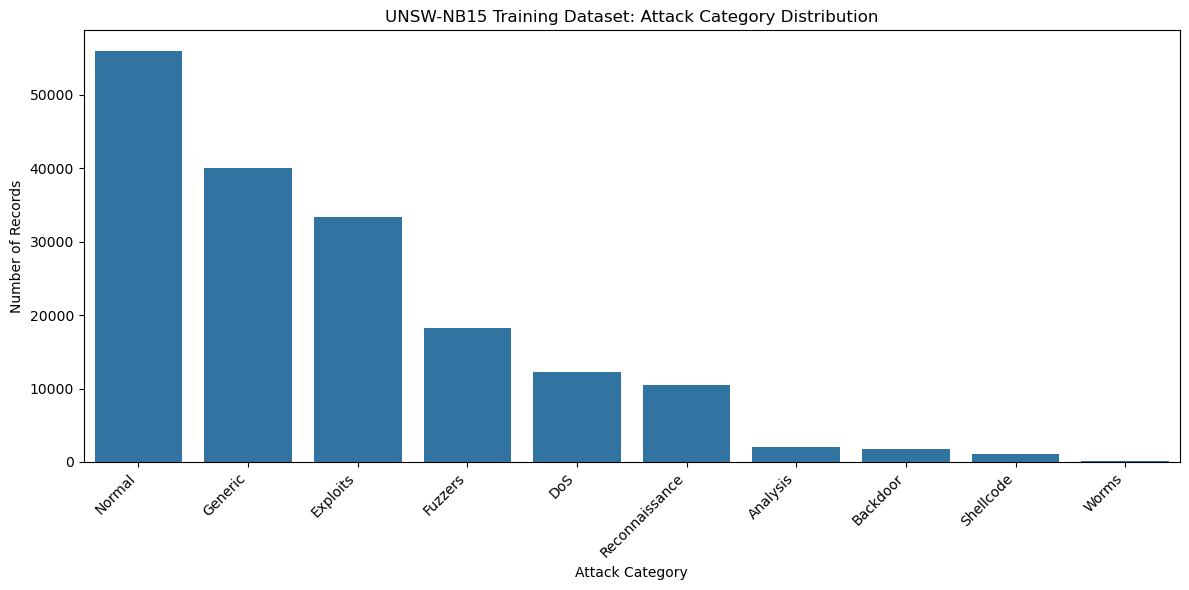


Rarest attack category: Worms
Number of Worms records: 130

STEP 3 COMPLETED!


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count each attack category in the training dataset
attack_counts = train_data["attack_cat"].value_counts()

# Display attack counts
print("Attack Category Distribution in Training Data:\n")
print(attack_counts)

# Calculate percentage of each category
attack_percentages = (
    train_data["attack_cat"].value_counts(normalize=True) * 100
).round(2)

print("\nAttack Category Percentages:\n")
print(attack_percentages)

# Plot attack category distribution
plt.figure(figsize=(12, 6))

sns.barplot(
    x=attack_counts.index,
    y=attack_counts.values
)

plt.title("UNSW-NB15 Training Dataset: Attack Category Distribution")
plt.xlabel("Attack Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Highlight the rare Worms category
print("\nRarest attack category:", attack_counts.idxmin())
print("Number of Worms records:",
      attack_counts.get("Worms", 0))

print("\nSTEP 3 COMPLETED!")

# Step 4 — Install and import CTGAN

In [13]:
%pip install ctgan

Note: you may need to restart the kernel to use updated packages.


In [14]:
import ctgan
from ctgan import CTGAN

print("CTGAN imported successfully!")
print("CTGAN version:", ctgan.__version__)

CTGAN imported successfully!
CTGAN version: 0.12.1


# Step 5 — Prepare the rare attack data and train CTGAN

In [15]:
from ctgan import CTGAN
import pandas as pd
import numpy as np

# 1. Select Worms records from training data only
worms_data = train_data[
    train_data["attack_cat"] == "Worms"
].copy()

print("Original Worms records:", len(worms_data))

# 2. Select traffic features for synthetic generation
# Exclude identifiers and target columns
excluded_columns = ["id", "attack_cat", "label"]

worms_features = worms_data.drop(
    columns=excluded_columns
).copy()

# 3. Identify categorical features
categorical_columns = worms_features.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nFeatures used for CTGAN:", worms_features.shape[1])
print("Categorical features:", categorical_columns)

# 4. Check data before training
print("\nMissing values:", worms_features.isnull().sum().sum())
print("Duplicate records:", worms_features.duplicated().sum())

# 5. Train CTGAN
# A moderate epoch count is a starting point for this small dataset.
ctgan_model = CTGAN(
    epochs=100,
    batch_size=50,
    verbose=True
)

ctgan_model.fit(
    worms_features,
    discrete_columns=categorical_columns
)

print("\nCTGAN training completed successfully!")

Original Worms records: 130

Features used for CTGAN: 42
Categorical features: ['proto', 'service', 'state']

Missing values: 0
Duplicate records: 3


Gen. (+00.65) | Discrim. (-01.08): 100%|██████████| 100/100 [00:12<00:00,  7.69it/s]


CTGAN training completed successfully!


# Step 6 — Generate synthetic rare samples

In [16]:
# Generate 500 synthetic Worms traffic records
synthetic_worms = ctgan_model.sample(500)

print("Synthetic data generated successfully!")
print("Synthetic dataset shape:", synthetic_worms.shape)

print("\nFirst 5 synthetic records:")
display(synthetic_worms.head())

print("\nData types:")
print(synthetic_worms.dtypes)

print("\nMissing values in synthetic data:",
      synthetic_worms.isnull().sum().sum())

print("\nDuplicate synthetic rows:",
      synthetic_worms.duplicated().sum())

print("\nSTEP 6 COMPLETED!")

Synthetic data generated successfully!
Synthetic dataset shape: (500, 42)

First 5 synthetic records:


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
0,-0.536349,udp,http,INT,17,288,157,-60716,18055.190160,256,...,2,1,1,1,0,0,1,0,1,0
1,3.318961,tcp,http,FIN,9,-37,1564,-62260,8136.933876,255,...,1,1,1,1,0,0,-1,3,1,0
2,1.794826,tcp,http,FIN,20,-34,3695,-7404,14102.689084,256,...,1,1,1,1,0,0,1,0,1,0
3,-0.687526,udp,http,INT,11,202,3995,-36969,-6900.466355,258,...,4,2,1,1,0,0,0,0,1,0
4,0.080648,tcp,http,FIN,22,-22,2683,41408,20695.525385,253,...,3,1,1,1,0,0,1,-1,1,0



Data types:
dur                  float64
proto                 object
service               object
state                 object
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm             int64
ct_src_dport_ltm       int64
c

# Step 7 — Validate synthetic data

In [17]:
# 1. Check negative values in numeric columns
numeric_cols = synthetic_worms.select_dtypes(
    include=["number"]
).columns

negative_counts = (
    synthetic_worms[numeric_cols] < 0
).sum()

print("Negative values per column:")
print(negative_counts[negative_counts > 0])

# 2. Check impossible packet and byte counts
count_columns = [
    "spkts", "dpkts", "sbytes", "dbytes",
    "sloss", "dloss", "trans_depth",
    "response_body_len", "ct_srv_src",
    "ct_state_ttl", "ct_dst_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm",
    "ct_dst_src_ltm", "ct_ftp_cmd",
    "ct_flw_http_mthd", "ct_src_ltm",
    "ct_srv_dst"
]

print("\nNegative count values:")
for col in count_columns:
    if col in synthetic_worms.columns:
        n = (synthetic_worms[col] < 0).sum()
        if n > 0:
            print(f"{col}: {n}")

# 3. Check TTL ranges
for col in ["sttl", "dttl"]:
    if col in synthetic_worms.columns:
        invalid = (
            (synthetic_worms[col] < 0) |
            (synthetic_worms[col] > 255)
        )
        print(f"\nInvalid {col} values: {invalid.sum()}")
        print(synthetic_worms.loc[invalid, col].head(10).tolist())

# 4. Check numeric summary
print("\nNumeric feature summary:")
display(synthetic_worms[numeric_cols].describe().T)

print("\nValidation diagnostic completed.")

Negative values per column:
dur                  321
spkts                  3
dpkts                343
sbytes                19
dbytes               258
rate                 108
dttl                  14
sload                 68
dload                371
sloss                 13
dloss                 35
sinpkt               327
dinpkt                60
sjit                 323
djit                 106
swin                  49
stcpb                131
dtcpb                 25
dwin                 208
tcprtt               355
synack                26
ackdat                40
smean                 71
dmean                271
response_body_len    428
ct_flw_http_mthd      93
ct_src_ltm           111
dtype: int64

Negative count values:
spkts: 3
dpkts: 343
sbytes: 19
dbytes: 258
sloss: 13
dloss: 35
response_body_len: 428
ct_flw_http_mthd: 93
ct_src_ltm: 111

Invalid sttl values: 259
[256, 256, 258, 261, 257, 256, 262, 256, 262, 257]

Invalid dttl values: 279
[267, 265, 268, 267, -82, -46, 259

,count,mean,std,min,25%,50%,75%,max
dur,500.0,-1.205839e-01,1.660654e+00,-1.507124e+01,-6.940203e-01,-2.645327e-01,3.086695e-01,8.174716e+00
spkts,500.0,3.618400e+01,3.966051e+01,-4.000000e+00,1.300000e+01,1.800000e+01,5.000000e+01,2.070000e+02
dpkts,500.0,7.300000e-01,1.488624e+02,-4.140000e+02,-4.000000e+01,-1.900000e+01,8.000000e+00,9.260000e+02
sbytes,500.0,2.512798e+03,4.523797e+03,-1.638000e+03,1.553000e+03,2.356000e+03,3.115750e+03,9.848100e+04
dbytes,500.0,4.734000e+00,6.240364e+04,-7.185400e+04,-2.802550e+04,-3.014500e+03,1.972450e+04,1.079478e+06
rate,500.0,5.585151e+04,1.231284e+05,-2.578400e+05,1.075735e+03,1.010826e+04,2.030011e+04,8.192560e+05
sttl,500.0,2.551720e+02,8.783662e+00,8.600000e+01,2.520000e+02,2.560000e+02,2.590000e+02,2.650000e+02
dttl,500.0,2.135660e+02,8.576003e+01,-1.080000e+02,1.642500e+02,2.570000e+02,2.670000e+02,2.790000e+02
sload,500.0,3.756021e+08,7.119599e+08,-1.456200e+08,2.248250e+07,5.866162e+07,9.468034e+07,2.910493e+09
dload,500.0,1.464452e+04,1.804937e+05,-1.101471e+05,-6.740845e+04,-4.328270e+04,1.032432e+03,1.076515e+06



Validation diagnostic completed.


In [18]:
# STEP 7: COMPARE REAL AND SYNTHETIC WORMS DATA

columns_to_check = [
    "dur", "spkts", "dpkts", "sbytes", "dbytes",
    "rate", "sttl", "dttl", "sload", "dload",
    "sloss", "dloss", "sinpkt", "dinpkt",
    "swin", "dwin", "tcprtt", "synack",
    "ackdat", "response_body_len",
    "ct_flw_http_mthd", "ct_src_ltm"
]

print("REAL WORMS DATA — SUMMARY")
display(worms_features[columns_to_check].describe().T)

print("\nSYNTHETIC WORMS DATA — SUMMARY")
display(synthetic_worms[columns_to_check].describe().T)

print("\nREAL WORMS DATA — NEGATIVE VALUES")
real_negative = (worms_features[columns_to_check] < 0).sum()
print(real_negative[real_negative > 0])

print("\nREAL WORMS DATA — TTL RANGES")
for col in ["sttl", "dttl"]:
    print(
        f"{col}: minimum = {worms_features[col].min()}, "
        f"maximum = {worms_features[col].max()}"
    )

REAL WORMS DATA — SUMMARY


,count,mean,std,min,25%,50%,75%,max
dur,130.0,1.428988e+00,2.316363e+00,0.000002,0.268738,0.548669,1.257584,1.588733e+01
spkts,130.0,1.870769e+01,2.454404e+01,2.000000,10.000000,10.000000,10.000000,1.160000e+02
dpkts,130.0,6.483077e+01,1.546324e+02,0.000000,6.000000,6.000000,8.000000,6.980000e+02
sbytes,130.0,2.403438e+03,6.926380e+03,92.000000,1284.500000,1302.000000,1314.000000,7.848100e+04
dbytes,130.0,7.968168e+04,2.079066e+05,0.000000,268.000000,268.000000,354.000000,9.153020e+05
rate,130.0,2.085749e+04,7.005720e+04,1.070035,23.146663,42.922151,77.635316,5.000000e+05
sttl,130.0,2.480923e+02,3.328511e+01,62.000000,254.000000,254.000000,254.000000,2.540000e+02
dttl,130.0,2.229231e+02,8.082181e+01,0.000000,252.000000,252.000000,252.000000,2.520000e+02
sload,130.0,7.375536e+07,2.897796e+08,585.624023,7442.031983,15698.249025,35621.801755,1.640000e+09
dload,130.0,1.297531e+05,2.933175e+05,0.000000,2065.691284,4065.873413,7354.573120,1.178738e+06



SYNTHETIC WORMS DATA — SUMMARY


,count,mean,std,min,25%,50%,75%,max
dur,500.0,-1.205839e-01,1.660654e+00,-1.507124e+01,-6.940203e-01,-2.645327e-01,3.086695e-01,8.174716e+00
spkts,500.0,3.618400e+01,3.966051e+01,-4.000000e+00,1.300000e+01,1.800000e+01,5.000000e+01,2.070000e+02
dpkts,500.0,7.300000e-01,1.488624e+02,-4.140000e+02,-4.000000e+01,-1.900000e+01,8.000000e+00,9.260000e+02
sbytes,500.0,2.512798e+03,4.523797e+03,-1.638000e+03,1.553000e+03,2.356000e+03,3.115750e+03,9.848100e+04
dbytes,500.0,4.734000e+00,6.240364e+04,-7.185400e+04,-2.802550e+04,-3.014500e+03,1.972450e+04,1.079478e+06
rate,500.0,5.585151e+04,1.231284e+05,-2.578400e+05,1.075735e+03,1.010826e+04,2.030011e+04,8.192560e+05
sttl,500.0,2.551720e+02,8.783662e+00,8.600000e+01,2.520000e+02,2.560000e+02,2.590000e+02,2.650000e+02
dttl,500.0,2.135660e+02,8.576003e+01,-1.080000e+02,1.642500e+02,2.570000e+02,2.670000e+02,2.790000e+02
sload,500.0,3.756021e+08,7.119599e+08,-1.456200e+08,2.248250e+07,5.866162e+07,9.468034e+07,2.910493e+09
dload,500.0,1.464452e+04,1.804937e+05,-1.101471e+05,-6.740845e+04,-4.328270e+04,1.032432e+03,1.076515e+06



REAL WORMS DATA — NEGATIVE VALUES
Series([], dtype: int64)

REAL WORMS DATA — TTL RANGES
sttl: minimum = 62, maximum = 254
dttl: minimum = 0, maximum = 252


In [19]:
# STEP 7: RETRAIN CTGAN WITH IMPROVED SETTINGS

from ctgan import CTGAN

# Use the original real Worms features
worms_features = worms_data.drop(
    columns=["id", "attack_cat", "label"]
).copy()

categorical_columns = worms_features.select_dtypes(
    include=["object"]
).columns.tolist()

print("Real Worms records:", len(worms_features))
print("Feature count:", len(worms_features.columns))
print("Categorical columns:", categorical_columns)

# Train a new CTGAN model
ctgan_model = CTGAN(
    epochs=500,
    batch_size=50,
    verbose=True
)

ctgan_model.fit(
    worms_features,
    discrete_columns=categorical_columns
)

print("CTGAN retraining completed.")

Real Worms records: 130
Feature count: 42
Categorical columns: ['proto', 'service', 'state']


Gen. (-05.96) | Discrim. (-01.25): 100%|██████████| 500/500 [01:01<00:00,  8.19it/s]

CTGAN retraining completed.


In [20]:
# Generate new synthetic Worms records
synthetic_worms = ctgan_model.sample(500)

print("Synthetic data shape:", synthetic_worms.shape)
display(synthetic_worms.head())

Synthetic data shape: (500, 42)


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
0,0.456870,tcp,-,FIN,-2,45,5175,11822,7315.457483,245,...,1,1,1,1,0,0,1,0,1,0
1,-3.703800,tcp,-,INT,20,91,14347,54382,15306.062054,254,...,1,1,1,1,0,0,5,0,1,0
2,1.218177,udp,-,INT,5,817,2582,28418,1629.996146,252,...,1,1,1,1,0,0,1,1,4,0
3,7.347705,udp,-,FIN,18,39,2741,17844,6802.970528,250,...,1,1,1,1,0,0,1,0,1,0
4,-0.168890,tcp,http,CON,6,0,3238,-37365,141916.919119,247,...,2,1,1,1,0,0,0,0,1,0


In [21]:
# Validate the newly generated data
numeric_cols = synthetic_worms.select_dtypes(
    include=["number"]
).columns

negative_counts = (synthetic_worms[numeric_cols] < 0).sum()

print("Negative values per column:")
print(negative_counts[negative_counts > 0])

print("\nInvalid TTL values:")
for col in ["sttl", "dttl"]:
    invalid = (
        (synthetic_worms[col] < 0) |
        (synthetic_worms[col] > 255)
    )
    print(f"{col}: {invalid.sum()}")

Negative values per column:
dur                   61
spkts                 17
dpkts                 46
sbytes                24
dbytes               255
rate                 185
sttl                  14
dttl                  83
sload                132
dload                 27
sloss                  9
dloss                114
sinpkt               374
dinpkt                37
sjit                  33
djit                 266
swin                  24
stcpb                 77
dtcpb                 32
dwin                  60
tcprtt               231
synack               112
ackdat               188
smean                  9
dmean                 36
trans_depth           32
response_body_len    243
ct_state_ttl           5
ct_dst_ltm             4
ct_dst_src_ltm        10
ct_flw_http_mthd      46
ct_src_ltm            43
dtype: int64

Invalid TTL values:
sttl: 85
dttl: 200


In [22]:
# STEP 7: INSPECT REAL WORMS FEATURE DATA TYPES

print("Feature data types:")
display(worms_features.dtypes.to_frame(name="Data Type"))

print("\nNumeric feature count:")
print(
    len(worms_features.select_dtypes(include=["number"]).columns)
)

print("\nCategorical feature count:")
print(
    len(worms_features.select_dtypes(include=["object"]).columns)
)

print("\nReal Worms data sample:")
display(worms_features.head())

Feature data types:


,Data Type
dur,float64
proto,object
service,object
state,object
spkts,int64
dpkts,int64
sbytes,int64
dbytes,int64
rate,float64
sttl,int64



Numeric feature count:
39

Categorical feature count:
3

Real Worms data sample:


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
49959,0.338518,tcp,http,FIN,66,14,78481,612,233.370165,254,...,1,1,1,1,0,0,1,1,1,0
50077,0.383961,tcp,http,FIN,14,6,8682,268,49.484193,254,...,1,1,1,1,0,0,1,1,1,0
51266,0.000005,udp,-,INT,2,0,2050,0,200000.005100,254,...,1,1,1,1,0,0,0,1,2,0
51904,0.544871,tcp,http,FIN,10,6,1282,268,27.529453,254,...,2,1,1,1,0,0,1,1,7,0
52833,1.598383,tcp,http,FIN,10,8,1292,354,10.635749,254,...,1,1,1,1,0,0,1,1,1,0


In [23]:
# STEP 7: PREPARE A TRANSFORMED COPY FOR CTGAN

import numpy as np
import pandas as pd

worms_transformed = worms_features.copy()

numeric_columns = worms_transformed.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify numeric columns that contain only nonnegative values
nonnegative_columns = [
    col for col in numeric_columns
    if (worms_transformed[col] >= 0).all()
]

print("Numeric columns:", len(numeric_columns))
print("Nonnegative numeric columns:", len(nonnegative_columns))

# Apply log1p to nonnegative numeric features
for col in nonnegative_columns:
    worms_transformed[col] = np.log1p(worms_transformed[col])

print("\nTransformed data preview:")
display(worms_transformed.head())

print("\nChecking for missing or infinite values:")
print("Missing values:", worms_transformed.isna().sum().sum())
print("Infinite values:", np.isinf(
    worms_transformed.select_dtypes(include=["number"])
).sum().sum())

Numeric columns: 39
Nonnegative numeric columns: 39

Transformed data preview:


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
49959,0.291563,tcp,http,FIN,4.204693,2.708050,11.270625,6.418365,5.456902,5.541264,...,0.693147,0.693147,0.693147,0.693147,0.0,0.0,0.693147,0.693147,0.693147,0.0
50077,0.324950,tcp,http,FIN,2.708050,1.945910,9.069122,5.594711,3.921660,5.541264,...,0.693147,0.693147,0.693147,0.693147,0.0,0.0,0.693147,0.693147,0.693147,0.0
51266,0.000005,udp,-,INT,1.098612,0.000000,7.626083,0.000000,12.206078,5.541264,...,0.693147,0.693147,0.693147,0.693147,0.0,0.0,0.000000,0.693147,1.098612,0.0
51904,0.434940,tcp,http,FIN,2.397895,1.945910,7.156956,5.594711,3.350937,5.541264,...,1.098612,0.693147,0.693147,0.693147,0.0,0.0,0.693147,0.693147,2.079442,0.0
52833,0.954889,tcp,http,FIN,2.397895,2.197225,7.164720,5.872118,2.454082,5.541264,...,0.693147,0.693147,0.693147,0.693147,0.0,0.0,0.693147,0.693147,0.693147,0.0



Checking for missing or infinite values:
Missing values: 0
Infinite values: 0


In [24]:
# STEP 7: TRAIN CTGAN ON TRANSFORMED WORMS DATA

from ctgan import CTGAN

categorical_columns = worms_transformed.select_dtypes(
    include=["object"]
).columns.tolist()

ctgan_model = CTGAN(
    epochs=500,
    batch_size=50,
    verbose=True
)

ctgan_model.fit(
    worms_transformed,
    discrete_columns=categorical_columns
)

print("CTGAN training on transformed data completed.")

Gen. (-00.33) | Discrim. (-04.03): 100%|██████████| 500/500 [01:08<00:00,  7.31it/s]

CTGAN training on transformed data completed.


In [25]:
# Generate 500 synthetic samples
synthetic_worms_transformed = ctgan_model.sample(500)

# Reverse the log1p transformation
synthetic_worms = synthetic_worms_transformed.copy()

numeric_columns = worms_features.select_dtypes(
    include=["number"]
).columns.tolist()

for col in numeric_columns:
    synthetic_worms[col] = np.expm1(
        synthetic_worms_transformed[col]
    )

print("Synthetic data shape:", synthetic_worms.shape)
display(synthetic_worms.head())

Synthetic data shape: (500, 42)


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
0,0.786064,udp,http,FIN,2.664058,5.018658,8.868260,502.409861,44.569027,265.717801,...,4.779864,0.998477,1.030159,1.068247,-0.001587,0.003087,0.104197,5.797770,1.056593,0.000556
1,0.680432,udp,http,CON,10.556437,7.654441,889.675957,123531.950986,6545.564028,269.992101,...,0.984391,1.056950,1.020865,1.110697,-0.002707,0.002124,0.198287,46.894813,0.966563,-0.001605
2,1.140372,tcp,-,INT,11.880620,142.620838,841.480760,166.238505,27.488261,269.655774,...,1.512831,0.948483,1.001335,1.009197,0.000457,0.001887,-0.028060,1.644459,0.964366,-0.001440
3,0.993798,udp,-,INT,15.364645,21.436675,1410.526900,300.563931,1709.051310,261.215313,...,1.018508,1.410018,0.964399,1.095731,-0.000628,0.001753,-0.092812,2.654020,1.012679,0.002999
4,0.481882,tcp,http,FIN,11.383126,4.900021,1384.697889,517.842591,2842.174464,263.942282,...,0.835647,0.978361,1.014403,11.380033,-0.001979,0.002079,0.956519,1.290999,1.333733,0.000252


In [26]:
# STEP 7: CHECK SYNTHETIC DATA QUALITY

print("Negative numeric values:")
numeric_cols = synthetic_worms.select_dtypes(
    include=["number"]
).columns

negative_counts = (synthetic_worms[numeric_cols] < 0).sum()
print(negative_counts[negative_counts > 0])

print("\nReal vs synthetic ranges:")
for col in [
    "dur", "spkts", "dpkts", "sbytes", "dbytes",
    "rate", "sttl", "dttl", "swin", "dwin",
    "is_ftp_login", "is_sm_ips_ports"
]:
    print(f"\n{col}")
    print(
        "Real:      ",
        worms_features[col].min(),
        "to",
        worms_features[col].max()
    )
    print(
        "Synthetic: ",
        synthetic_worms[col].min(),
        "to",
        synthetic_worms[col].max()
    )

Negative numeric values:
dur                  107
dpkts                104
dbytes                39
dttl                  99
dload                126
sloss                 70
dloss                 11
sinpkt               130
dinpkt                58
sjit                  50
djit                 114
swin                 130
stcpb                 75
dtcpb                 28
dwin                  30
tcprtt               114
synack                53
ackdat                92
dmean                 31
trans_depth          116
response_body_len    235
ct_state_ttl          21
is_ftp_login         384
ct_ftp_cmd           105
ct_flw_http_mthd      88
is_sm_ips_ports      173
dtype: int64

Real vs synthetic ranges:

dur
Real:       2e-06 to 15.887326
Synthetic:  -0.5336653343057784 to 29.27321831580144

spkts
Real:       2 to 116
Synthetic:  0.0018202139960360303 to 342.6019079328701

dpkts
Real:       0 to 698
Synthetic:  -0.912012624865107 to 3034.0944359171526

sbytes
Real:       92 to 78481


In [27]:
# STEP 7: RESET TO ORIGINAL REAL WORMS DATA

# Restore the original, untransformed real features
worms_features = worms_data.drop(
    columns=["id", "attack_cat", "label"]
).copy()

# Confirm the rare-class count
print("Real Worms records:", len(worms_features))
print("Feature count:", len(worms_features.columns))

# Check constant features
constant_columns = [
    col for col in worms_features.columns
    if worms_features[col].nunique() <= 1
]

print("\nConstant features in real Worms data:")
print(constant_columns)

# Confirm original data has no missing values
print(
    "\nMissing values:",
    worms_features.isna().sum().sum()
)

print(
    "Duplicate feature rows:",
    worms_features.duplicated().sum()
)

Real Worms records: 130
Feature count: 42

Constant features in real Worms data:
['is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']

Missing values: 0
Duplicate feature rows: 3


In [28]:
# STEP 7: IDENTIFY FEATURE TYPES

print("Categorical features:")
print(worms_features.select_dtypes(include=["object"]).columns.tolist())

print("\nBinary features:")
binary_columns = [
    col for col in worms_features.columns
    if worms_features[col].nunique() <= 2
]
print(binary_columns)

print("\nInteger-valued numeric features:")
integer_columns = [
    col for col in worms_features.select_dtypes(include=["number"]).columns
    if (worms_features[col] % 1 == 0).all()
]
print(integer_columns)

print("\nContinuous numeric features:")
continuous_columns = [
    col for col in worms_features.select_dtypes(include=["number"]).columns
    if col not in integer_columns
]
print(continuous_columns)

Categorical features:
['proto', 'service', 'state']

Binary features:
['proto', 'service', 'sttl', 'dttl', 'swin', 'dwin', 'trans_depth', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']

Integer-valued numeric features:
['spkts', 'dpkts', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'swin', 'stcpb', 'dtcpb', 'dwin', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']

Continuous numeric features:
['dur', 'rate', 'sload', 'dload', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat']


In [29]:
# STEP 7: CONTROLLED SYNTHETIC SAMPLE GENERATION

import numpy as np
import pandas as pd

np.random.seed(42)

# Start from the original real Worms records
real_worms = worms_features.copy()

# Continuous numeric features only
continuous_columns = [
    "dur", "rate", "sload", "dload", "sinpkt",
    "dinpkt", "sjit", "djit", "tcprtt", "synack", "ackdat"
]

# Draw 500 source rows with replacement
synthetic_worms = real_worms.sample(
    n=500,
    replace=True,
    random_state=42
).reset_index(drop=True)

# Add small Gaussian perturbations to continuous features
for col in continuous_columns:
    real_values = pd.to_numeric(real_worms[col], errors="raise")
    scale = real_values.std()

    if pd.notna(scale) and scale > 0:
        noise = np.random.normal(
            loc=0,
            scale=0.01 * scale,
            size=len(synthetic_worms)
        )

        synthetic_worms[col] = (
            synthetic_worms[col].astype(float) + noise
        )

        # Keep generated values within the real observed range
        synthetic_worms[col] = synthetic_worms[col].clip(
            lower=real_values.min(),
            upper=real_values.max()
        )

print("Candidate synthetic records:", len(synthetic_worms))
print("Number of features:", len(synthetic_worms.columns))
print("\nPreview:")
display(synthetic_worms.head())

Candidate synthetic records: 500
Number of features: 42

Preview:


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
0,0.271751,tcp,http,FIN,10,6,1302,268,706.492065,254,...,1,1,1,1,0,0,1,1,1,0
1,2.570307,tcp,http,FIN,38,200,2002,263543,1429.775986,254,...,2,1,1,1,0,0,1,1,2,0
2,3.718101,tcp,http,FIN,48,230,2440,308245,1.070035,254,...,1,1,1,1,0,0,1,3,1,0
3,0.769599,tcp,http,FIN,10,8,1296,354,417.551162,254,...,2,1,1,1,0,0,1,1,1,0
4,1.888717,tcp,http,FIN,10,8,1308,354,1.070035,254,...,1,2,1,1,0,0,1,2,2,0


In [30]:
# STEP 7: VALIDATE CANDIDATE SYNTHETIC DATA

# 1. Check missing values
print("Missing values:", synthetic_worms.isna().sum().sum())

# 2. Check negative values in continuous features
print("\nNegative continuous values:")
print(
    (synthetic_worms[continuous_columns] < 0).sum()
)

# 3. Check whether integer and categorical features were preserved
preserved_columns = [
    col for col in worms_features.columns
    if col not in continuous_columns
]

print(
    "\nNon-continuous features unchanged:",
    all(
        synthetic_worms[col].isin(worms_features[col]).all()
        for col in preserved_columns
    )
)

# 4. Check whether continuous features remain within real ranges
print("\nContinuous feature range checks:")
for col in continuous_columns:
    real_min = worms_features[col].min()
    real_max = worms_features[col].max()

    synthetic_min = synthetic_worms[col].min()
    synthetic_max = synthetic_worms[col].max()

    valid = synthetic_min >= real_min and synthetic_max <= real_max

    print(
        f"{col}: valid_range={valid}, "
        f"real=({real_min:.6g}, {real_max:.6g}), "
        f"synthetic=({synthetic_min:.6g}, {synthetic_max:.6g})"
    )

# 5. Check exact duplicates against original Worms records
original_rows = set(
    pd.util.hash_pandas_object(worms_features, index=False)
)
synthetic_hashes = pd.util.hash_pandas_object(
    synthetic_worms, index=False
)

print(
    "\nSynthetic rows exactly matching original rows:",
    synthetic_hashes.isin(original_rows).sum(),
    "out of",
    len(synthetic_worms)
)

Missing values: 0

Negative continuous values:
dur       0
rate      0
sload     0
dload     0
sinpkt    0
dinpkt    0
sjit      0
djit      0
tcprtt    0
synack    0
ackdat    0
dtype: int64

Non-continuous features unchanged: True

Continuous feature range checks:
dur: valid_range=True, real=(2e-06, 15.8873), synthetic=(2e-06, 15.8873)
rate: valid_range=True, real=(1.07004, 500000), synthetic=(1.07004, 500000)
sload: valid_range=True, real=(585.624, 1.64e+09), synthetic=(585.624, 1.64e+09)
dload: valid_range=True, real=(0, 1.17874e+06), synthetic=(0, 1.17874e+06)
sinpkt: valid_range=True, real=(0.002, 1765.25), synthetic=(0.002, 1765.25)
dinpkt: valid_range=True, real=(0, 2256.68), synthetic=(0, 2256.68)
sjit: valid_range=True, real=(0, 119206), synthetic=(0, 119206)
djit: valid_range=True, real=(0, 3604.43), synthetic=(0, 3604.43)
tcprtt: valid_range=True, real=(0, 0.402079), synthetic=(0, 0.402079)
synack: valid_range=True, real=(0, 0.150467), synthetic=(0, 0.150467)
ackdat: valid_

In [31]:
# STEP 7: COMPARE REAL AND SYNTHETIC FEATURE DISTRIBUTIONS

comparison_columns = [
    "dur", "rate", "sload", "dload",
    "sinpkt", "dinpkt", "sjit", "djit",
    "tcprtt", "synack", "ackdat"
]

comparison_results = []

for col in comparison_columns:
    real_mean = worms_features[col].mean()
    synthetic_mean = synthetic_worms[col].mean()

    real_std = worms_features[col].std()
    synthetic_std = synthetic_worms[col].std()

    comparison_results.append({
        "Feature": col,
        "Real Mean": real_mean,
        "Synthetic Mean": synthetic_mean,
        "Real Std": real_std,
        "Synthetic Std": synthetic_std
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Feature,Real Mean,Synthetic Mean,Real Std,Synthetic Std
0,dur,1.429000e+00,1.298700e+00,2.316400e+00,2.014600e+00
1,rate,2.085749e+04,1.699334e+04,7.005720e+04,5.612714e+04
2,sload,7.375536e+07,7.079898e+07,2.897796e+08,2.814085e+08
3,dload,1.297531e+05,1.257544e+05,2.933175e+05,2.885211e+05
4,sinpkt,7.810250e+01,7.101070e+01,1.604894e+02,1.215270e+02
5,dinpkt,9.219810e+01,8.440500e+01,2.049989e+02,1.553271e+02
6,sjit,4.612987e+03,4.115552e+03,1.081746e+04,8.122648e+03
7,djit,4.155666e+02,3.938601e+02,6.490455e+02,6.101268e+02
8,tcprtt,1.235000e-01,1.229000e-01,7.360000e-02,7.640000e-02
9,synack,5.910000e-02,5.860000e-02,3.790000e-02,3.840000e-02


In [32]:
# STEP 7: COMPARE FEATURE CORRELATIONS

real_corr = worms_features[continuous_columns].corr()
synthetic_corr = synthetic_worms[continuous_columns].corr()

# Compare correlations across all feature pairs
corr_difference = (real_corr - synthetic_corr).abs()

upper_triangle = np.triu(
    np.ones(corr_difference.shape, dtype=bool),
    k=1
)

mean_corr_difference = corr_difference.where(upper_triangle).stack().mean()

print(
    "Mean absolute correlation difference:",
    round(mean_corr_difference, 4)
)

print("\nLargest correlation differences:")
largest_differences = (
    corr_difference.where(upper_triangle)
    .stack()
    .sort_values(ascending=False)
    .head(10)
)

display(largest_differences)

Mean absolute correlation difference: 0.033

Largest correlation differences:


dinpkt  djit      0.130142
dur     dinpkt    0.111665
sjit    djit      0.085881
sinpkt  djit      0.077819
dur     sjit      0.071875
djit    ackdat    0.070101
dur     sinpkt    0.064824
        ackdat    0.062284
sinpkt  tcprtt    0.059840
        synack    0.057273
dtype: float64

# Next: Step 8 — Prepare real-only and augmented datasets

In [33]:
# Dataset 1: Original training data
real_only_data = train_data.copy()

# Dataset 2: Original training data + candidate Worms samples
synthetic_worms_labeled = synthetic_worms.copy()
synthetic_worms_labeled["attack_cat"] = "Worms"
synthetic_worms_labeled["label"] = 1

# Match the original training column order
synthetic_worms_labeled = synthetic_worms_labeled[
    train_data.columns.drop("id")
]

# Keep original rows and add synthetic rows
augmented_data = pd.concat(
    [
        train_data.drop(columns=["id"]),
        synthetic_worms_labeled
    ],
    ignore_index=True
)

print("Real-only dataset shape:", real_only_data.shape)
print("Augmented dataset shape:", augmented_data.shape)

print("\nWorms count before augmentation:")
print(real_only_data["attack_cat"].value_counts().get("Worms", 0))

print("\nWorms count after augmentation:")
print(augmented_data["attack_cat"].value_counts().get("Worms", 0))

print("\nTest dataset shape:", test_data.shape)

Real-only dataset shape: (175341, 45)
Augmented dataset shape: (175841, 44)

Worms count before augmentation:
130

Worms count after augmentation:
630

Test dataset shape: (82332, 45)


In [34]:
# Remove identifier column from both datasets
real_only_data = train_data.drop(columns=["id"]).copy()

# Ensure both datasets use the same columns in the same order
augmented_data = augmented_data[real_only_data.columns]

print("Real-only dataset shape:", real_only_data.shape)
print("Augmented dataset shape:", augmented_data.shape)

print("\nColumns match:",
      real_only_data.columns.equals(augmented_data.columns))

print("\nWorms count in real-only data:",
      real_only_data["attack_cat"].value_counts().get("Worms", 0))

print("\nWorms count in augmented data:",
      augmented_data["attack_cat"].value_counts().get("Worms", 0))

print("\nMissing values in real-only data:",
      real_only_data.isna().sum().sum())

print("Missing values in augmented data:",
      augmented_data.isna().sum().sum())

Real-only dataset shape: (175341, 44)
Augmented dataset shape: (175841, 44)

Columns match: True

Worms count in real-only data: 130

Worms count in augmented data: 630

Missing values in real-only data: 0
Missing values in augmented data: 0


# Step 9 — Train two Random Forest classifiers

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.impute import SimpleImputer

# Separate features and target
X_real = real_only_data.drop(columns=["attack_cat", "label"])
y_real = real_only_data["attack_cat"]

X_augmented = augmented_data.drop(columns=["attack_cat", "label"])
y_augmented = augmented_data["attack_cat"]

# Use the original test set for both models
test_data_model = test_data.drop(columns=["id"]).copy()
X_test = test_data_model.drop(columns=["attack_cat", "label"])
y_test = test_data_model["attack_cat"]

# Identify categorical and numerical columns
categorical_features = X_real.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_real.select_dtypes(
    include=["number"]
).columns.tolist()

# Preprocessing: encode categories and preserve numeric features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        ),
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numerical_features
        )
    ]
)

# Model 1: Real-only data
real_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

print("Training Random Forest on real-only data...")
real_model.fit(X_real, y_real)

# Model 2: Augmented data
augmented_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

print("Training Random Forest on augmented data...")
augmented_model.fit(X_augmented, y_augmented)

print("\nBoth models trained successfully.")


Training Random Forest on real-only data...
Training Random Forest on augmented data...

Both models trained successfully.


# Step 10 — Compare model performance.

In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Predictions on the same untouched test set
y_pred_real = real_model.predict(X_test)
y_pred_augmented = augmented_model.predict(X_test)

# Overall performance metrics
results = []

for model_name, y_pred in [
    ("Real-only Random Forest", y_pred_real),
    ("Augmented Random Forest", y_pred_augmented)
]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Weighted Precision": precision,
        "Weighted Recall": recall,
        "Weighted F1-score": f1
    })

results_df = pd.DataFrame(results)

print("OVERALL MODEL COMPARISON")
display(results_df.round(4))

# Detailed performance for the rare Worms class
print("\nWORMS CLASS PERFORMANCE")

for model_name, y_pred in [
    ("Real-only Random Forest", y_pred_real),
    ("Augmented Random Forest", y_pred_augmented)
]:
    report = classification_report(
        y_test,
        y_pred,
        labels=["Worms"],
        output_dict=True,
        zero_division=0
    )

    print(f"\n{model_name}")
    print("Precision:", round(report["Worms"]["precision"], 4))
    print("Recall:", round(report["Worms"]["recall"], 4))
    print("F1-score:", round(report["Worms"]["f1-score"], 4))

# Worms confusion counts
print("\nWORMS DETECTION COUNTS")

for model_name, y_pred in [
    ("Real-only Random Forest", y_pred_real),
    ("Augmented Random Forest", y_pred_augmented)
]:
    actual_worms = y_test == "Worms"
    predicted_worms = y_pred == "Worms"

    true_positives = (actual_worms & predicted_worms).sum()
    false_negatives = (actual_worms & ~predicted_worms).sum()
    false_positives = (~actual_worms & predicted_worms).sum()

    print(f"\n{model_name}")
    print("True positives:", true_positives)
    print("False negatives:", false_negatives)
    print("False positives:", false_positives)


OVERALL MODEL COMPARISON


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-score
0,Real-only Random Forest,0.7496,0.8373,0.7496,0.7835
1,Augmented Random Forest,0.7497,0.8379,0.7497,0.7840



WORMS CLASS PERFORMANCE

Real-only Random Forest
Precision: 0.5833
Recall: 0.1591
F1-score: 0.25

Augmented Random Forest
Precision: 0.7333
Recall: 0.25
F1-score: 0.3729

WORMS DETECTION COUNTS

Real-only Random Forest
True positives: 7
False negatives: 37
False positives: 5

Augmented Random Forest
True positives: 11
False negatives: 33
False positives: 4


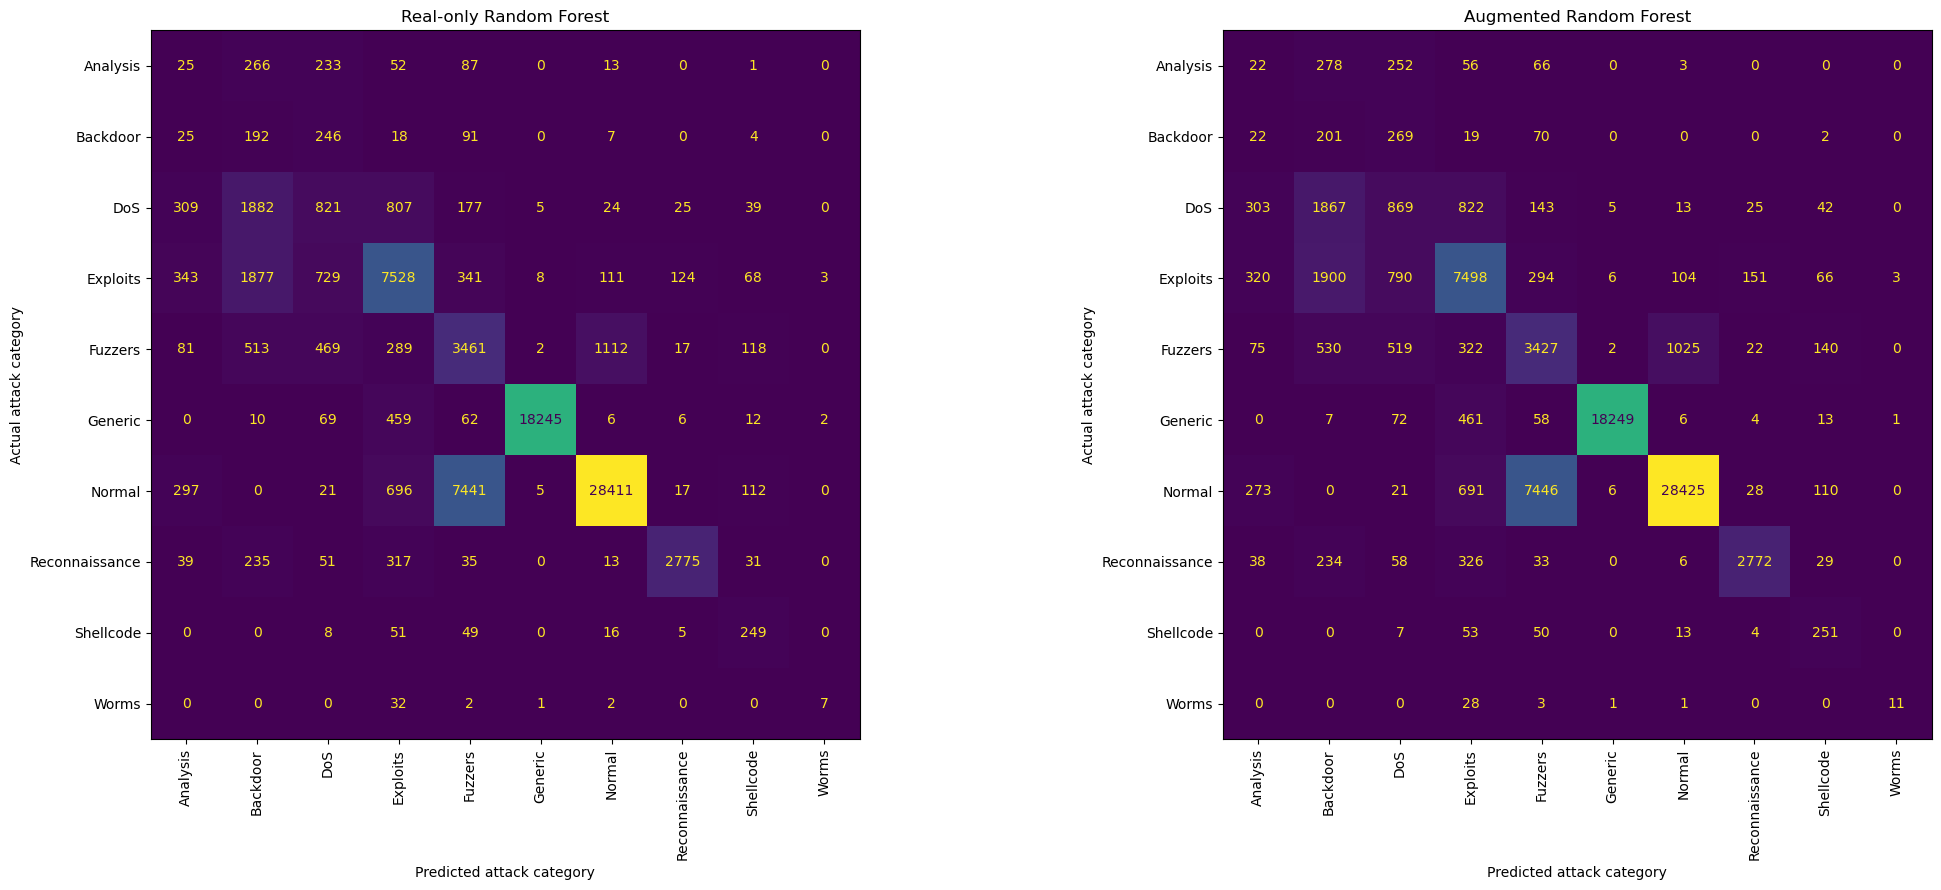

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use the same class order for both models
class_labels = sorted(y_test.unique())

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

models = [
    ("Real-only Random Forest", real_model),
    ("Augmented Random Forest", augmented_model)
]

for ax, (model_name, model) in zip(axes, models):
    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=class_labels
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display.plot(
        ax=ax,
        xticks_rotation=90,
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted attack category")
    ax.set_ylabel("Actual attack category")

plt.tight_layout()
plt.show()


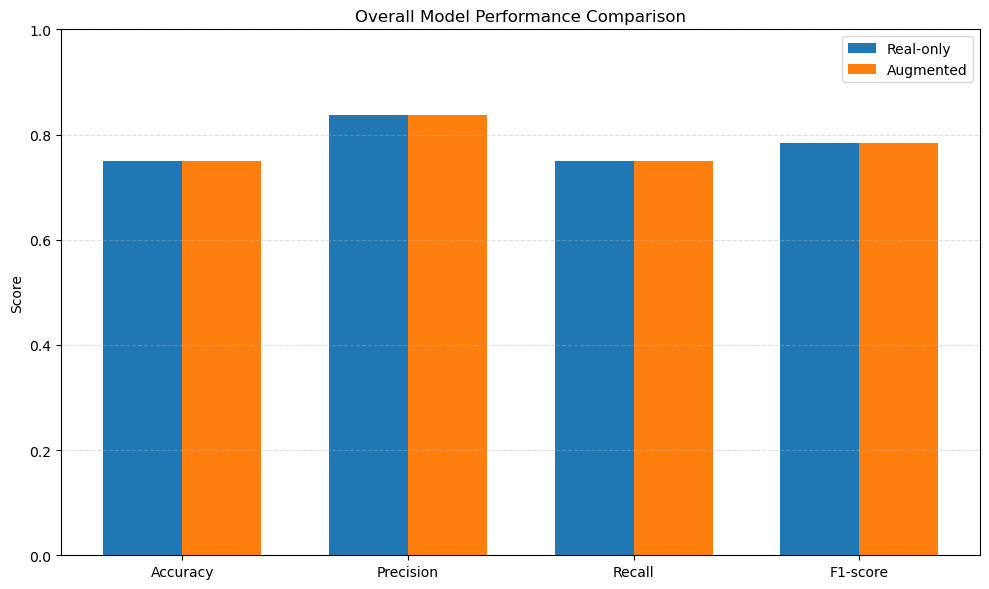

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

real_scores = [0.7496, 0.8373, 0.7496, 0.7835]
augmented_scores = [0.7497, 0.8379, 0.7497, 0.7840]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, real_scores, width, label="Real-only")
plt.bar(x + width/2, augmented_scores, width, label="Augmented")

plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Overall Model Performance Comparison")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

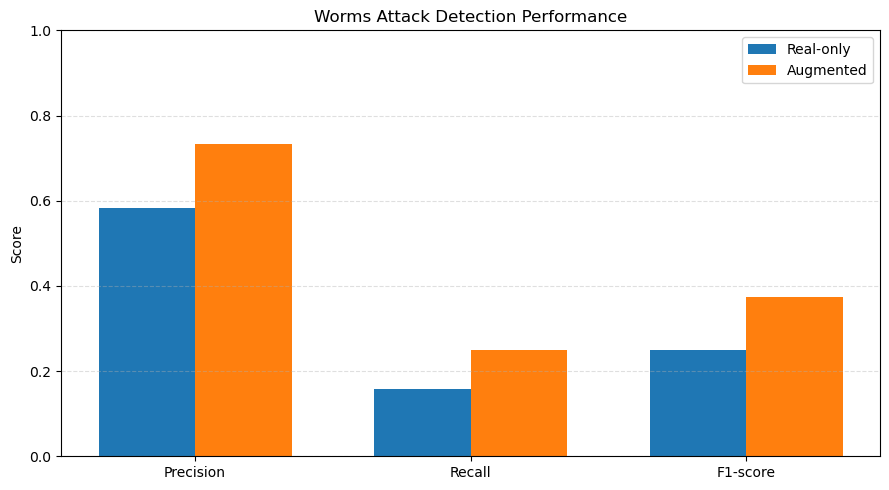

In [39]:
worms_metrics = ["Precision", "Recall", "F1-score"]

real_worms_scores = [0.5833, 0.1591, 0.2500]
augmented_worms_scores = [0.7333, 0.2500, 0.3729]

x = np.arange(len(worms_metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, real_worms_scores, width, label="Real-only")
plt.bar(x + width/2, augmented_worms_scores, width, label="Augmented")

plt.xticks(x, worms_metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Worms Attack Detection Performance")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()